# 6.4 · 绩效指标进阶：全面评估策略

> 单看"年化收益"会误导：高收益可能伴随高风险、高回撤、靠运气。
> 专业评估要从**风险调整收益、交易统计、分年度稳定性、基准对比**多个维度。
> 本节学会用一套完整指标给策略"体检"，并理解每个指标的含义和局限。

## 一、风险调整收益指标

| 指标 | 公式 | 含义 |
|---|---|---|
| 夏普 | $(r-r_f)/\sigma$ | 单位总风险的超额，最常用 |
| Sortino | $(r-r_f)/\sigma_{down}$ | 只惩罚下行波动 |
| Calmar | 年化收益 / 最大回撤 | 收益对极端亏损 |
| 信息比率 | 超额均值/跟踪误差 | 单位主动风险的超额 |
| 特雷诺 | $(r-r_f)/\beta$ | 单位系统性风险 |

> 夏普看总风险，信息比率看相对基准的主动能力，Sortino 更关注"亏"的部分。

## 二、交易统计（日频/单笔）

- **胜率**：盈利次数占比；
- **盈亏比**：平均盈利 / 平均亏损；
- **期望值**：胜率×平均盈利 − 败率×平均亏损（长期每笔预期赚多少）；
- **最大连续亏损**：心理和资金压力的考验。

> 高胜率不一定赚钱（盈亏比可能很低）；低胜率也能赚钱（靠大盈亏比，如趋势跟踪）。关键看**期望值是否为正**。

## 三、完整绩效报告（代码在 backtest_lab.performance）

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
from factor_lab.library import build_factors
from backtest_lab.engine import run_backtest
from backtest_lab.performance import full_report, yearly_returns
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
F = D.features(codes, ['$close','$volume','$mkt_cap_ard','$pe_ttm','$pb_lf'], freq='day')
close = F['$close'].unstack('instrument')
facs = build_factors(close, F['$volume'].unstack('instrument'),
                     F['$mkt_cap_ard'].unstack('instrument'),
                     F['$pe_ttm'].unstack('instrument'),
                     F['$pb_lf'].unstack('instrument'))
sp = facs['SMB 小市值']
W = pd.DataFrame(0.0, index=sp.index, columns=sp.columns)
for dt in sp.index:
    top = sp.loc[dt].dropna().nlargest(30)
    W.loc[dt, top.index] = 1.0/30
W = W.loc['2024-01-01':]; c = close.loc[W.index]
bt = run_backtest(W, c, cost_bps=20)
bm = pd.read_csv(r'C:\Users\gucao\Desktop\Qlib\data\benchmark\000300_sh.csv',
                 parse_dates=['date']).set_index('date')['close']
b = bm.pct_change().reindex(bt['return'].index).fillna(0)
print(full_report(bt['return'], b).round(3))

[22616:MainThread](2026-10-30 01:50:28,718) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[22616:MainThread](2026-10-30 01:50:30,201) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[22616:MainThread](2026-10-30 01:50:30,202) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


年化收益       0.427
年化波动       0.277
夏普         1.420
Sortino    2.292
Calmar     1.979
最大回撤      -0.215
胜率         0.519
盈亏比        1.201
期望值        0.002
最大连亏       7.000
Alpha      0.299
Beta       1.189
信息比率       1.782
dtype: float64


## 四、分年度收益：稳定性

             组合     基准
datetime              
2024      0.686  0.162
2025      0.783  0.177
2026     -0.094 -0.127


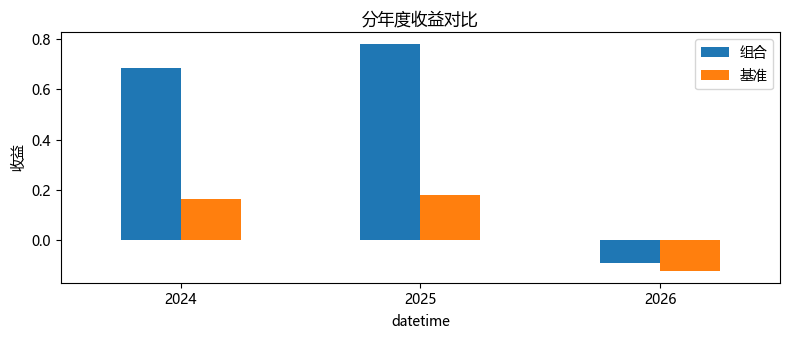

In [2]:
yr = pd.DataFrame({'组合': yearly_returns(bt['return']),
                  '基准': yearly_returns(b)})
print(yr.round(3))
yr.plot(kind='bar', figsize=(8, 3.5))
plt.title('分年度收益对比'); plt.ylabel('收益'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 五、滚动指标：能力是否持续

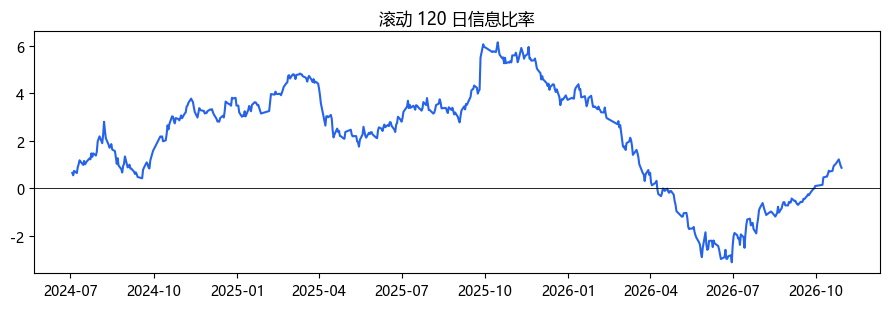

滚动IR为正的比例: 0.79


In [3]:
# 滚动 120 日信息比率
active = (bt['return'] - b)
roll_ir = active.rolling(120).mean() / active.rolling(120).std() * np.sqrt(242)
plt.figure(figsize=(9, 3.2))
plt.plot(roll_ir, color='#2563eb'); plt.axhline(0, color='black', lw=.6)
plt.title('滚动 120 日信息比率'); plt.tight_layout(); plt.show()
print('滚动IR为正的比例: %.2f' % (roll_ir.dropna() > 0).mean())

## 六、指标的局限（避免唯指标论）

- 指标都基于历史，不代表未来；
- 夏普等假设收益近似正态、无自相关，极端尾部、肥尾会低估风险；
- 短期/单一区间的指标不稳定，要看长期、滚动、分年度；
- 不同策略不能只比夏普（如 CTA 与市场中性、期权卖方的夏普虚高但尾部风险大）。

> 绩效评估要结合：收益来源是否可解释、风险是否可控、能力是否持续、容量是否足够。

## 七、小结与面试要点

- 风险调整：夏普、Sortino、Calmar、信息比率、特雷诺。
- 交易统计：胜率、盈亏比、期望值、最大连亏；期望值为正才是根本。
- 要看分年度、滚动指标的稳定性；指标有局限，需结合收益来源和风险。

**面试高频：**
- 夏普和信息比率的区别？（答：夏普对总风险/无风险，信息比率对跟踪误差/基准）
- 胜率高的策略一定好吗？（答：不一定，盈亏比可能低，要看期望值）
- 怎么全面评估一个策略？（答：风险调整指标、回撤、分年度稳定性、超额持续性、容量）
- 夏普比率有什么局限？（答：假设正态、对肥尾和非对称风险估计不足）

## 动手练习
1. 计算月度收益热力图，看季节性；
2. 对比不同 N 的组合的完整报告；
3. 用滚动夏普判断策略能力是否衰减。

---
下一节 **6.5 绩效归因：Brinson 与多因子归因**。